# **Heart Disease Prediction Using Naive Bayes**

## **1. Project Overview**

This project aims to build a machine learning classification model using the Naive Bayes algorithm to predict the presence or absence of heart disease based on patient health attributes.

The project involves data exploration, preprocessing, model training, and performance evaluation.

## **2. Objectives**

- Explore and understand the heart disease dataset.
- Perform exploratory data analysis (EDA).
- Prepare the dataset for machine learning.
- Train a Gaussian Naive Bayes classifier.
- Evaluate model performance using appropriate classification metrics.
- Interpret the results and document the findings.

## **3. Technologies Used**

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab

## **4. Problem Statement**

To develop a classification model that identifies patterns associated with the presence of heart disease using patient health attributes.

## **5. Importing Required Libraries**

Import the Python libraries required for data manipulation, visualization, preprocessing, model training, and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## **6. Loading the Dataset**

I will load the heart disease dataset into a Pandas DataFrame and inspect its structure before performing any analysis.

In [2]:
file_path = "/content/drive/MyDrive/Data Science Projeccts/heart_attack/heart.csv"
df = pd.read_csv(file_path)

print("Dataset uploaded successfully")

Dataset uploaded successfully


## **7. Initial Data Inspection**

Inspect the dataset to understand its dimensions, features, data types, and sample records.

In [3]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (303, 14)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## **8. Data Quality Checks**

### **8.1 Checking Missing Values**

Missing values are entries that have no recorded data in a particular column. Identifying them is important because they can affect data analysis and model performance.

Calculate the number of missing values in each column to determine whether any preprocessing is required.

In [7]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


### **8.2 Checking Duplicate Records**

Duplicate records are rows that contain exactly the same values across all columns.

Checking duplicates helps us identify repeated records that could affect our analysis. However, we should investigate duplicates before removing them because identical patient records are not necessarily errors.

In [8]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 1


In [9]:
df[df.duplicated()]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


In [10]:
# Remove duplicate rows
df = df.drop_duplicates()

# Reset the index
df = df.reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (302, 14)
Remaining duplicate rows: 0


## **9. Exploratory Data Analysis (EDA)**

### **9.1 Understanding the Target Variable**

The target variable represents the outcome that our machine learning model will predict.

Inspect the dataset's column names to identify the correct target column. In this dataset, it may be named `target`, but we must verify this before proceeding.

In [11]:
print("Column names:")
print(df.columns.tolist())

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


### **9.2 Distribution of Target Classes**

Count the records belonging to each target class to understand how the dataset is distributed between the two outcomes.


In [12]:
df["target"].value_counts()

,count
target,
1,164
0,138


### **9.3 Visualizing Target Distribution**

A count plot displays the number of records in each target class.

This visualization helps us identify whether the classes are approximately balanced or whether one class has considerably more records than the other.

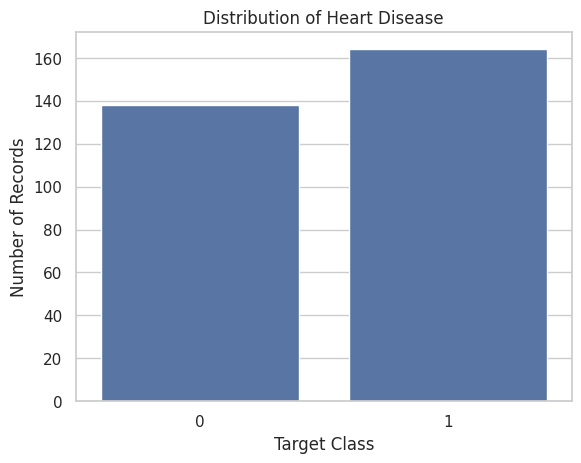

In [13]:
sns.countplot(data=df, x="target")

plt.title("Distribution of Heart Disease")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")
plt.show()

## **Analyze Individual Features**

### **9.4 Distribution of Age**

Age is an important numerical feature in the dataset. We use a histogram to examine how patient ages are distributed.

The histogram groups ages into intervals called bins, while the height of each bar represents the number of observations within that interval.

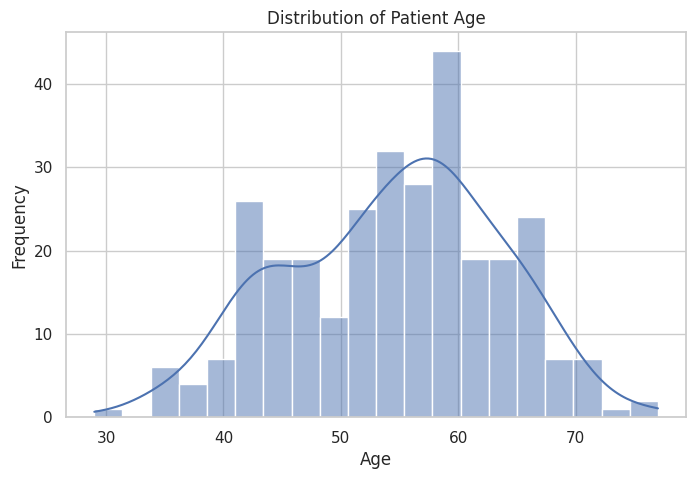

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20, kde=True)

plt.title("Distribution of Patient Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

### **9.5 Relationship Between Age and Target**

Compare the age distributions of the two target classes using box plots.

A box plot displays the median, quartiles, and potential outliers, helping us examine differences in age between the classes.

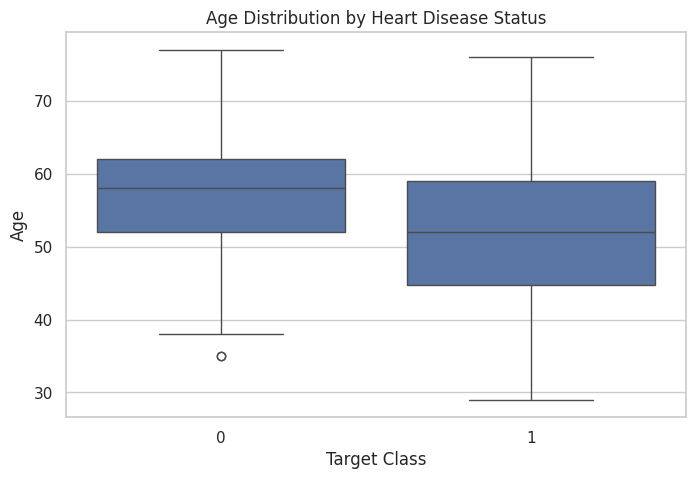

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="target", y="age")

plt.title("Age Distribution by Heart Disease Status")
plt.xlabel("Target Class")
plt.ylabel("Age")
plt.show()

## **Analyse Categorical Features**

### **9.6 Gender Distribution**

The `sex` column represents the gender category recorded in the dataset. We use a count plot to examine the number of observations in each category.

This helps us understand the distribution of gender within the dataset.

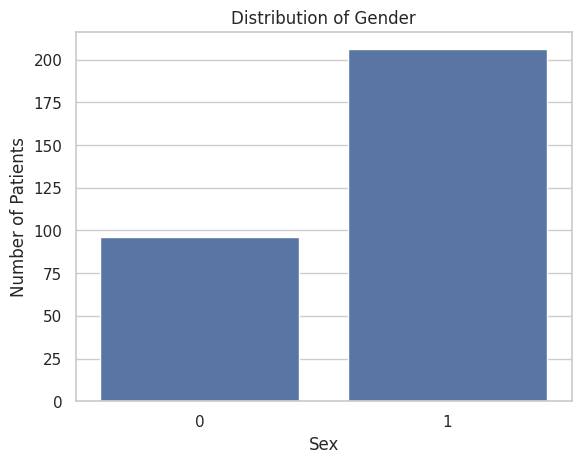

In [16]:
sns.countplot(data=df, x="sex")

plt.title("Distribution of Gender")
plt.xlabel("Sex")
plt.ylabel("Number of Patients")
plt.show()

### **9.7 Chest Pain Type Distribution**

The `cp` column represents chest pain type. We examine its distribution to understand how frequently each category occurs.

Comparing chest pain categories with the target variable may also reveal patterns in the dataset.

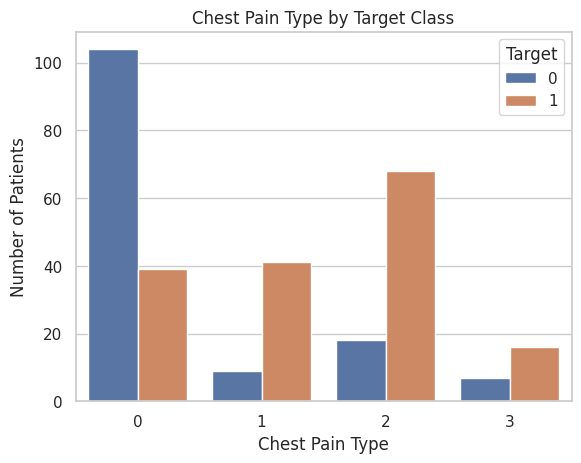

In [17]:
sns.countplot(data=df, x="cp", hue="target")

plt.title("Chest Pain Type by Target Class")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Patients")
plt.legend(title="Target")
plt.show()

### **9.8 Exercise-Induced Angina**

The `exang` column records whether exercise-induced angina is present.

Compare its categories with the target variable to examine how the observations are distributed across the two target classes.

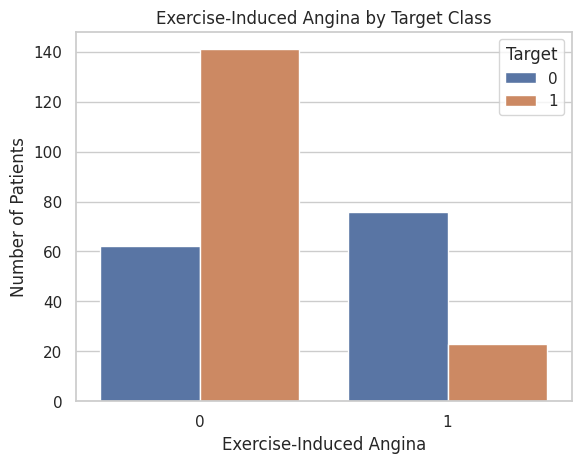

In [18]:
sns.countplot(data=df, x="exang", hue="target")

plt.title("Exercise-Induced Angina by Target Class")
plt.xlabel("Exercise-Induced Angina")
plt.ylabel("Number of Patients")
plt.legend(title="Target")
plt.show()

## **Analyse Numerical Features**

### **9.9 Cholesterol Distribution**

The `chol` column represents serum cholesterol measurements.

Using histogram with a KDE curve to examine the distribution of cholesterol values and identify concentrations or possible extreme observations.

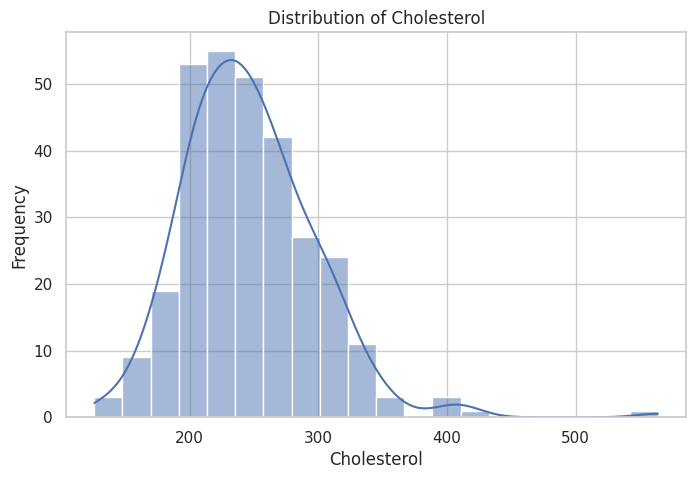

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="chol", bins=20, kde=True)

plt.title("Distribution of Cholesterol")
plt.xlabel("Cholesterol")
plt.ylabel("Frequency")
plt.show()

### **9.10 Maximum Heart Rate by Target Class**

The `thalach` column represents the maximum heart rate recorded during the test.

Using box plots to compare its distribution between the two target classes.

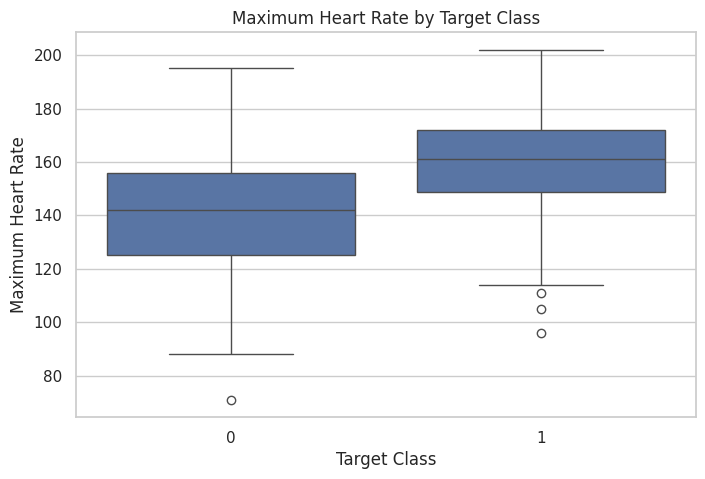

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="target", y="thalach")

plt.title("Maximum Heart Rate by Target Class")
plt.xlabel("Target Class")
plt.ylabel("Maximum Heart Rate")
plt.show()

### **9.11 Correlation Analysis**

Correlation measures the strength and direction of a linear relationship between numerical variables.

Calculate the Pearson correlation matrix to examine relationships between the dataset's numerical columns, including the target variable.


In [21]:
correlation_matrix = df.corr(numeric_only=True)

correlation_matrix

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.094962,-0.063107,0.283121,0.207216,0.119492,-0.111590,-0.395235,0.093216,0.206040,-0.164124,0.302261,0.065317,-0.221476
sex,-0.094962,1.000000,-0.051740,-0.057647,-0.195571,0.046022,-0.060351,-0.046439,0.143460,0.098322,-0.032990,0.113060,0.211452,-0.283609
cp,-0.063107,-0.051740,1.000000,0.046486,-0.072682,0.096018,0.041561,0.293367,-0.392937,-0.146692,0.116854,-0.195356,-0.160370,0.432080
trestbps,0.283121,-0.057647,0.046486,1.000000,0.125256,0.178125,-0.115367,-0.048023,0.068526,0.194600,-0.122873,0.099248,0.062870,-0.146269
chol,0.207216,-0.195571,-0.072682,0.125256,1.000000,0.011428,-0.147602,-0.005308,0.064099,0.050086,0.000417,0.086878,0.096810,-0.081437
fbs,0.119492,0.046022,0.096018,0.178125,0.011428,1.000000,-0.083081,-0.007169,0.024729,0.004514,-0.058654,0.144935,-0.032752,-0.026826
restecg,-0.111590,-0.060351,0.041561,-0.115367,-0.147602,-0.083081,1.000000,0.041210,-0.068807,-0.056251,0.090402,-0.083112,-0.010473,0.134874
thalach,-0.395235,-0.046439,0.293367,-0.048023,-0.005308,-0.007169,0.041210,1.000000,-0.377411,-0.342201,0.384754,-0.228311,-0.094910,0.419955
exang,0.093216,0.143460,-0.392937,0.068526,0.064099,0.024729,-0.068807,-0.377411,1.000000,0.286766,-0.256106,0.125377,0.205826,-0.435601
oldpeak,0.206040,0.098322,-0.146692,0.194600,0.050086,0.004514,-0.056251,-0.342201,0.286766,1.000000,-0.576314,0.236560,0.209090,-0.429146


### **9.12 Visualizing Correlations**

A correlation heatmap displays correlation coefficients using different shades and annotations.

It helps us identify potentially strong relationships between features and examine how numerical features correlate with the target variable.

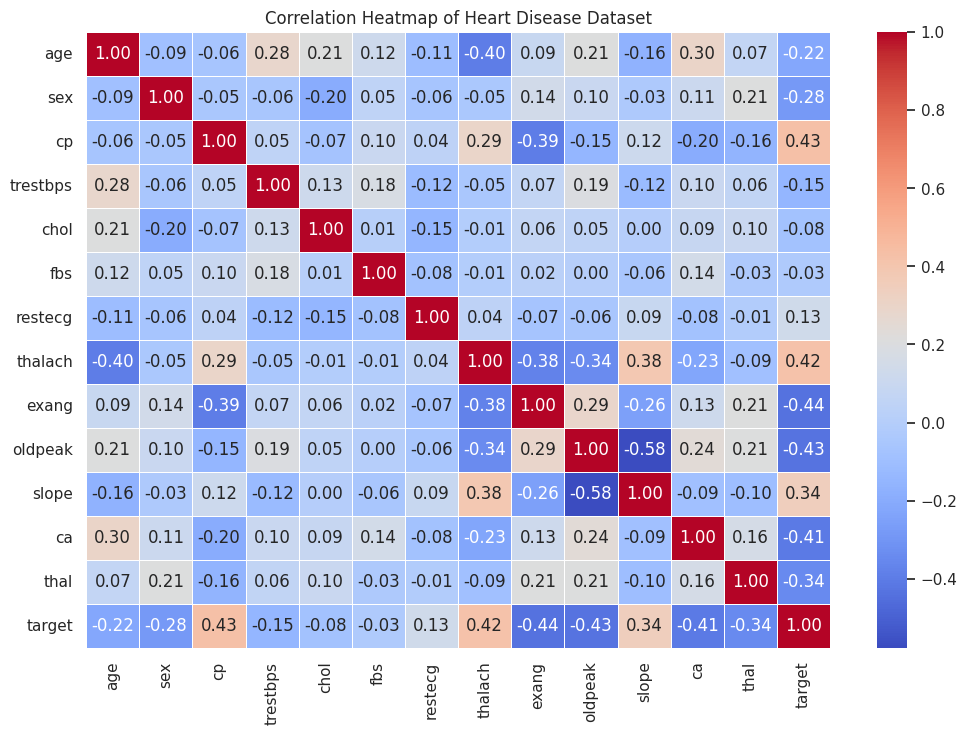

In [22]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Heart Disease Dataset")
plt.show()

# **10. Data Preprocessing**

### **10.1 Separating Features and Target**

Separating the independent features (X) from the target variable (y). The features will be used to predict the target, which indicates the presence or absence of heart disease.

In [23]:
X = df.drop("target", axis=1)
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (302, 13)
Target shape: (302,)


### **10.2 Checking Feature Data Types**

Check the feature data types to identify categorical columns that require encoding before model training.

In [24]:
X.dtypes

,0
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64


## **11. Splitting the Dataset**

Divide the dataset into training and testing sets. The training set is used to fit the model, while the testing set evaluates its performance on unseen observations.

I used ratio of 80:20 split and stratification to preserve the approximate target-class proportions in both sets.

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (241, 13)
Testing features: (61, 13)


## **12. Model Training**

### **12.1 Gaussian Naive Bayes**

Gaussian Naive Bayes is a probabilistic classification algorithm that applies Bayes' theorem and assumes that numerical features follow a Gaussian (normal) distribution within each class.

Train the model using the training dataset.

In [26]:
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


### **12.2 Making Predictions**

Using the trained model to predict the target classes for the testing dataset. These predictions will be compared with the actual target values to evaluate performance.

In [27]:
y_pred = model.predict(X_test)

print("Predictions:", y_pred[:10])

Predictions: [0 0 0 0 1 0 1 0 1 1]


## **13. Model Evaluation**

Evaluate the model using accuracy, precision, recall, and F1-score.

- Accuracy: Proportion of all predictions that are correct.
- Precision: Proportion of positive predictions that are correct.
- Recall: Proportion of actual positive cases correctly identified.
- F1-score: Harmonic mean of precision and recall.

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

results

,Metric,Score
0,Accuracy,0.819672
1,Precision,0.789474
2,Recall,0.909091
3,F1-Score,0.845070


## **13.1 Detailed Classification Report**

The classification report provides precision, recall, F1-score, and support for each target class.

This helps us understand how well the model classifies both classes rather than relying on accuracy alone.

In [29]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.87      0.71      0.78        28
           1       0.79      0.91      0.85        33

    accuracy                           0.82        61
   macro avg       0.83      0.81      0.81        61
weighted avg       0.83      0.82      0.82        61



### **13.2 Confusion Matrix**

A confusion matrix compares actual classes with predicted classes.

It shows true negatives, false positives, false negatives, and true positives, helping us identify the types of classification errors made by the model.

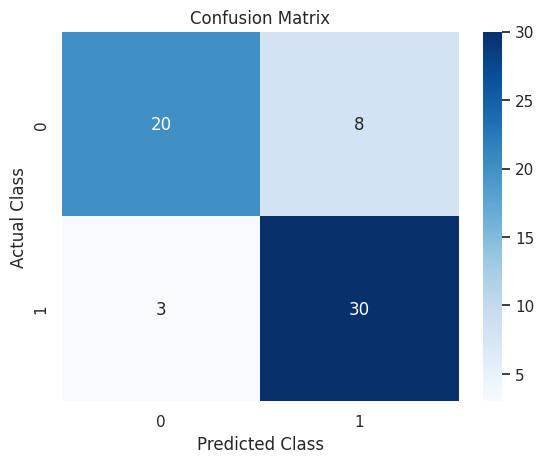

In [30]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

### **13.3 ROC Curve and ROC-AUC**

The ROC curve illustrates the trade-off between the true positive rate and false positive rate at different classification thresholds.

ROC-AUC measures how well the model distinguishes between the two classes. A higher score indicates better discrimination.

ROC-AUC Score: 0.8852813852813852


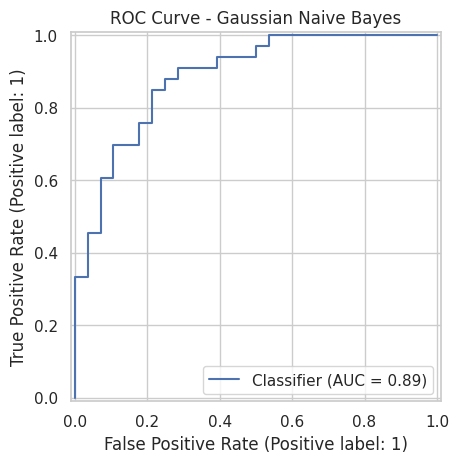

In [31]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

y_prob = model.predict_proba(X_test)[:, 1]

print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))

RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("ROC Curve - Gaussian Naive Bayes")
plt.show()

# **14. Conclusion**

In this project, I explored a heart disease dataset and developed a Gaussian Naive Bayes classification model. I evaluated its performance using accuracy, precision, recall, F1-score, a confusion matrix, and ROC-AUC.

The evaluation results help us understand the model's strengths and limitations on the testing dataset.

This project demonstrates the application of probability-based machine learning for binary classification.